In [2]:
import pandas as pd

Load the dataset

In [3]:
df = pd.read_csv("/Users/ishik/Desktop/practical-stats-for-data-scientist/chapter-01-eda/data/hour.csv",index_col="instant")

In [4]:
df.shape

(17379, 16)

In [5]:
df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
instant,,,,,,,,,,,,,,,,
1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 1 to 17379
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  str    
 1   season      17379 non-null  int64  
 2   yr          17379 non-null  int64  
 3   mnth        17379 non-null  int64  
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weekday     17379 non-null  int64  
 7   workingday  17379 non-null  int64  
 8   weathersit  17379 non-null  int64  
 9   temp        17379 non-null  float64
 10  atemp       17379 non-null  float64
 11  hum         17379 non-null  float64
 12  windspeed   17379 non-null  float64
 13  casual      17379 non-null  int64  
 14  registered  17379 non-null  int64  
 15  cnt         17379 non-null  int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 2.1 MB


Check for null values in all the columns

In [7]:
df.isnull().sum()

dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Check for duplicated rows

In [8]:
df.duplicated().sum()

np.int64(0)

Check if cnt column is sum of casual and registered column for all the rows

In [9]:
(df['cnt'] == df['casual'] + df['registered']).all()

np.True_

Fix the datatypes for the required columns

In [10]:
df['dteday'] = pd.to_datetime(df['dteday'])

In [11]:
cols = ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit']
df[cols] = df[cols].astype('category')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 1 to 17379
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      17379 non-null  datetime64[us]
 1   season      17379 non-null  category      
 2   yr          17379 non-null  category      
 3   mnth        17379 non-null  category      
 4   hr          17379 non-null  category      
 5   holiday     17379 non-null  category      
 6   weekday     17379 non-null  category      
 7   workingday  17379 non-null  category      
 8   weathersit  17379 non-null  category      
 9   temp        17379 non-null  float64       
 10  atemp       17379 non-null  float64       
 11  hum         17379 non-null  float64       
 12  windspeed   17379 non-null  float64       
 13  casual      17379 non-null  int64         
 14  registered  17379 non-null  int64         
 15  cnt         17379 non-null  int64         
dtypes: category(8), datetime64[us](1)

In [13]:
df.select_dtypes(include='number').describe()

,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Calculate the coefficient of variation for casual and registered columns

In [14]:
cv = (df[['casual','registered','cnt']].std()/df[['casual','registered','cnt']].mean()) 
cv

casual        1.382014
registered    0.984202
cnt           0.957377
dtype: float64

Calculate the 90th and 95th percentile for the cnt column

In [15]:
df['cnt'].quantile(0.90)

np.float64(451.2000000000007)

In [16]:
df['cnt'].quantile(0.95)

np.float64(563.0999999999985)

Calculate the skewness of the casual, registered and cnt columns

In [17]:
df[['casual','registered','cnt']].skew()

casual        2.499237
registered    1.557904
cnt           1.277412
dtype: float64

In [18]:
import matplotlib.pyplot as plt

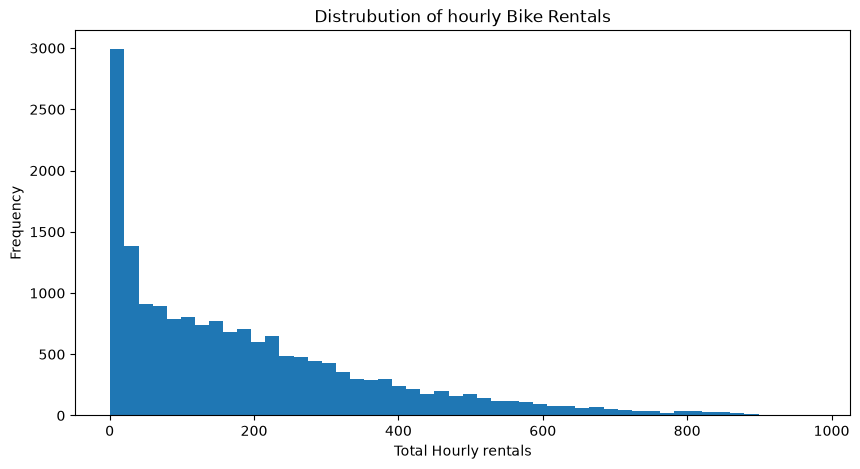

In [19]:
plt.figure(figsize=(10,5))
plt.hist(df['cnt'],bins=50)
plt.xlabel("Total Hourly rentals")
plt.ylabel("Frequency")
plt.title("Distrubution of hourly Bike Rentals")
plt.show()

/var/folders/k1/8_nwyhzd63x2h3q29fcsft7r0000gn/T/ipykernel_96106/3926681327.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['cnt'],vert=False)


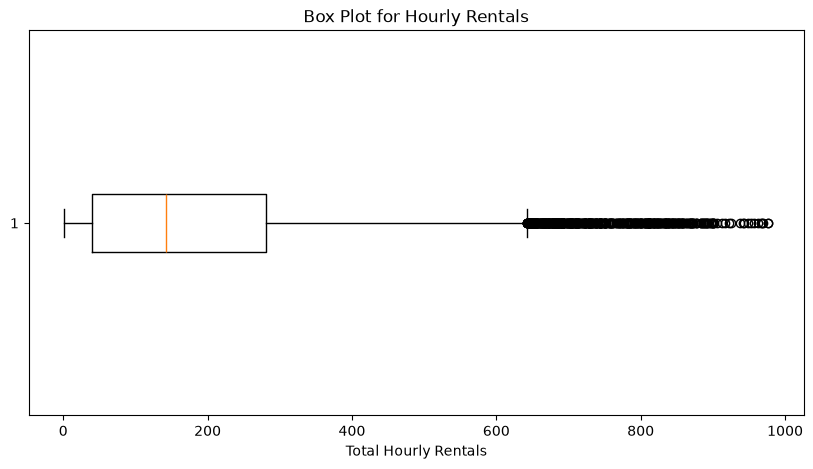

In [20]:
plt.figure(figsize=(10,5))
plt.boxplot(df['cnt'],vert=False)
plt.xlabel("Total Hourly Rentals")
plt.title("Box Plot for Hourly Rentals")
plt.show()

Investigate the outliers

In [23]:
q1 = df['cnt'].quantile(0.25)
q3 = df['cnt'].quantile(0.75)
IQR = q1-q3

Lower_bound = q3 + 1.5 *IQR
Upper_bound = q1 - 1.5 *IQR

outliers = df[(df['cnt'] > Lower_bound | df['cnt'] < Upper_bound)] 

outliers.head()

TypeError: Cannot perform 'ror_' with a dtyped [int64] array and scalar of type [bool]